<a href="https://colab.research.google.com/github/manikanta-eng/block-chain-/blob/main/assignment_12_block_chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 HYPERLEDGER FABRIC - PERSONAL ASSET PORTFOLIO MANAGEMENT

STEP 1: INITIALIZE BLOCKCHAIN LEDGER
-----------------------------------------------------------------
Ledger Initialized: SUCCESS
World State Initialized: SUCCESS

STEP 2: CHAINCODE INITIALIZATION
-----------------------------------------------------------------
Create Asset Function: AVAILABLE
View Assets Function: AVAILABLE
Transfer Ownership Function: AVAILABLE
Transaction History: AVAILABLE
Blockchain Verification: AVAILABLE

STEP 3: CREATE PERSONAL ASSETS
-----------------------------------------------------------------
Asset 1 Created: {'asset_id': 'A001', 'asset_name': 'Python Programming Certificate', 'asset_type': 'Certificate', 'owner': 'Manikanta', 'status': 'Active'}
Asset 2 Created: {'asset_id': 'A002', 'asset_name': 'AI Mock Interview Project', 'asset_type': 'Project', 'owner': 'Manikanta', 'status': 'Active'}
Asset 3 Created: {'asset_id': 'A003', 'asset_name': 'Blockchain Token', 'asset_type': 'Token', 'owner': 

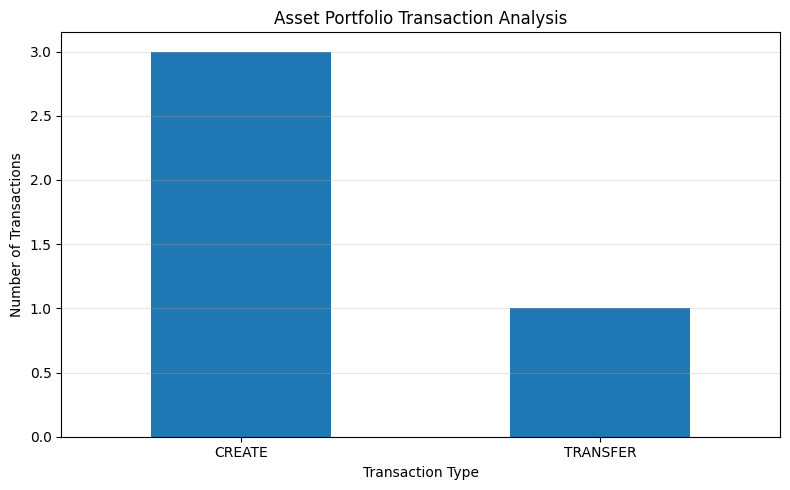

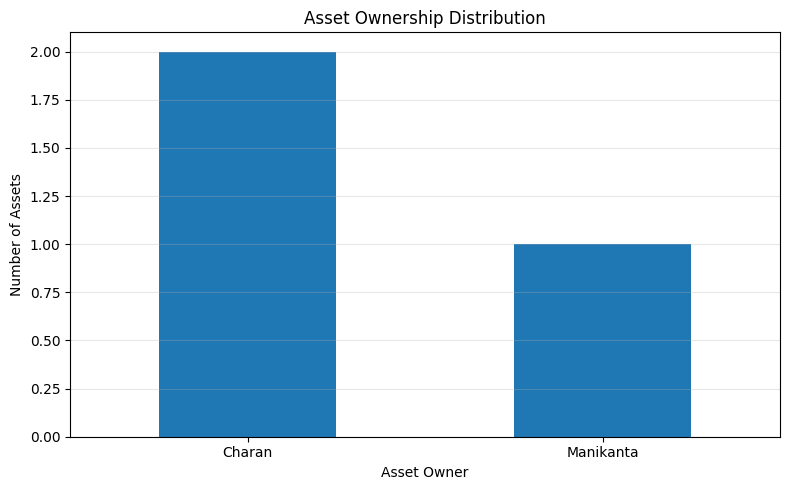


             FINAL PRACTICAL RESULTS
Ledger Initialization              : SUCCESS
Chaincode Initialization           : SUCCESS
Asset Creation                     : SUCCESS
View All Assets                    : SUCCESS
View Individual Asset              : SUCCESS
Ownership Transfer                 : SUCCESS
Access Control                     : PASSED
Transaction History                : SUCCESS
Blockchain Verification            : PASSED
Transaction Analysis               : SUCCESS
Graph Generation                   : SUCCESS
-----------------------------------------------------------------
Total Assets: 3
Total Transactions: 4
Final Owner of A001: Charan
Ledger Integrity: VALID
ALL PORTFOLIO SIMULATION TESTS COMPLETED!


In [1]:

# ============================================================
# BLOCKCHAIN ENGINEERING PRACTICAL
# HYPERLEDGER FABRIC - PERSONAL ASSET PORTFOLIO
# Google Colab - Complete Single Cell Code
# ============================================================

import hashlib
import json
import time
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print(" HYPERLEDGER FABRIC - PERSONAL ASSET PORTFOLIO MANAGEMENT")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1: INITIALIZE LEDGER
# ------------------------------------------------------------

ledger = []
world_state = {}

print("\nSTEP 1: INITIALIZE BLOCKCHAIN LEDGER")
print("-" * 65)

print("Ledger Initialized: SUCCESS")
print("World State Initialized: SUCCESS")

# ------------------------------------------------------------
# STEP 2: DEFINE SMART CONTRACT / CHAINCODE
# ------------------------------------------------------------

class AssetPortfolio:

    def __init__(self):
        self.assets = {}
        self.ledger = []

    # Generate transaction hash
    def generate_hash(self, transaction):

        data = json.dumps(
            transaction,
            sort_keys=True
        )

        return hashlib.sha256(
            data.encode()
        ).hexdigest()

    # Add transaction to ledger
    def add_transaction(self, operation, asset):

        previous_hash = (
            self.ledger[-1]["hash"]
            if self.ledger else "GENESIS"
        )

        transaction = {
            "transaction_id": len(self.ledger) + 1,
            "operation": operation,
            "asset": asset.copy(),
            "timestamp": datetime.now().isoformat(),
            "previous_hash": previous_hash
        }

        transaction["hash"] = self.generate_hash(
            transaction
        )

        self.ledger.append(transaction)

    # --------------------------------------------------------
    # FUNCTION 1: CREATE ASSET
    # --------------------------------------------------------

    def create_asset(self, asset_id, asset_name,
                     asset_type, owner):

        if asset_id in self.assets:
            raise ValueError("Asset already exists")

        if not all([asset_id, asset_name, asset_type, owner]):
            raise ValueError("All fields are required")

        asset = {
            "asset_id": asset_id,
            "asset_name": asset_name,
            "asset_type": asset_type,
            "owner": owner,
            "status": "Active"
        }

        self.assets[asset_id] = asset

        self.add_transaction("CREATE", asset)

        return asset

    # --------------------------------------------------------
    # FUNCTION 2: VIEW ALL ASSETS
    # --------------------------------------------------------

    def view_all_assets(self):

        return list(self.assets.values())

    # --------------------------------------------------------
    # FUNCTION 3: VIEW SINGLE ASSET
    # --------------------------------------------------------

    def view_asset(self, asset_id):

        if asset_id not in self.assets:
            raise ValueError("Asset not found")

        return self.assets[asset_id]

    # --------------------------------------------------------
    # FUNCTION 4: TRANSFER OWNERSHIP
    # --------------------------------------------------------

    def transfer_ownership(self, asset_id,
                           current_owner, new_owner):

        if asset_id not in self.assets:
            raise ValueError("Asset not found")

        if self.assets[asset_id]["owner"] != current_owner:
            raise PermissionError("Unauthorized owner")

        if not new_owner or new_owner == current_owner:
            raise ValueError("Invalid new owner")

        self.assets[asset_id]["owner"] = new_owner

        self.add_transaction(
            "TRANSFER",
            self.assets[asset_id]
        )

        return self.assets[asset_id]

    # --------------------------------------------------------
    # FUNCTION 5: TRANSACTION HISTORY
    # --------------------------------------------------------

    def transaction_history(self):

        return self.ledger

    # --------------------------------------------------------
    # FUNCTION 6: VERIFY BLOCKCHAIN INTEGRITY
    # --------------------------------------------------------

    def verify_blockchain(self):

        for i, transaction in enumerate(self.ledger):

            previous_hash = (
                self.ledger[i - 1]["hash"]
                if i > 0 else "GENESIS"
            )

            if transaction["previous_hash"] != previous_hash:
                return False

            transaction_data = {
                key: value
                for key, value in transaction.items()
                if key != "hash"
            }

            calculated_hash = self.generate_hash(
                transaction_data
            )

            if calculated_hash != transaction["hash"]:
                return False

        return True


# Create portfolio instance

portfolio = AssetPortfolio()

print("\nSTEP 2: CHAINCODE INITIALIZATION")
print("-" * 65)

print("Create Asset Function: AVAILABLE")
print("View Assets Function: AVAILABLE")
print("Transfer Ownership Function: AVAILABLE")
print("Transaction History: AVAILABLE")
print("Blockchain Verification: AVAILABLE")

# ------------------------------------------------------------
# STEP 3: CREATE ASSETS
# ------------------------------------------------------------

print("\nSTEP 3: CREATE PERSONAL ASSETS")
print("-" * 65)

start = time.time()

asset1 = portfolio.create_asset(
    "A001",
    "Python Programming Certificate",
    "Certificate",
    "Manikanta"
)

asset2 = portfolio.create_asset(
    "A002",
    "AI Mock Interview Project",
    "Project",
    "Manikanta"
)

asset3 = portfolio.create_asset(
    "A003",
    "Blockchain Token",
    "Token",
    "Charan"
)

create_time = time.time() - start

print("Asset 1 Created:", asset1)
print("Asset 2 Created:", asset2)
print("Asset 3 Created:", asset3)

print("\nAsset Creation: SUCCESS")
print("Execution Time:", round(create_time * 1000, 4), "ms")

# ------------------------------------------------------------
# STEP 4: VIEW ALL ASSETS
# ------------------------------------------------------------

print("\nSTEP 4: VIEW ALL ASSETS")
print("-" * 65)

all_assets = portfolio.view_all_assets()

asset_df = pd.DataFrame(all_assets)

print(asset_df.to_string(index=False))

print("\nTotal Assets:", len(all_assets))
print("Asset Retrieval: SUCCESS")

# ------------------------------------------------------------
# STEP 5: VIEW INDIVIDUAL ASSET
# ------------------------------------------------------------

print("\nSTEP 5: VIEW INDIVIDUAL ASSET")
print("-" * 65)

selected_asset = portfolio.view_asset("A001")

print(json.dumps(selected_asset, indent=4))

print("Individual Asset Retrieval: SUCCESS")

# ------------------------------------------------------------
# STEP 6: TRANSFER ASSET OWNERSHIP
# ------------------------------------------------------------

print("\nSTEP 6: TRANSFER ASSET OWNERSHIP")
print("-" * 65)

start = time.time()

transferred_asset = portfolio.transfer_ownership(
    "A001",
    "Manikanta",
    "Charan"
)

transfer_time = time.time() - start

print("Asset ID: A001")
print("Previous Owner: Manikanta")
print("New Owner: Charan")
print("Transferred Asset:", transferred_asset)

print("Ownership Transfer: SUCCESS")
print("Execution Time:", round(transfer_time * 1000, 4), "ms")

# ------------------------------------------------------------
# STEP 7: VERIFY UNAUTHORIZED TRANSFER
# ------------------------------------------------------------

print("\nSTEP 7: ACCESS CONTROL TEST")
print("-" * 65)

try:

    portfolio.transfer_ownership(
        "A001",
        "Manikanta",
        "AnotherUser"
    )

    print("Unexpected transfer result")

except PermissionError:

    print("Unauthorized transfer rejected")
    print("Access Control Test: PASSED")

# ------------------------------------------------------------
# STEP 8: DISPLAY UPDATED ASSET PORTFOLIO
# ------------------------------------------------------------

print("\nSTEP 8: UPDATED ASSET PORTFOLIO")
print("-" * 65)

updated_assets = portfolio.view_all_assets()

updated_df = pd.DataFrame(updated_assets)

print(updated_df.to_string(index=False))

# ------------------------------------------------------------
# STEP 9: DISPLAY TRANSACTION HISTORY
# ------------------------------------------------------------

print("\nSTEP 9: BLOCKCHAIN TRANSACTION HISTORY")
print("-" * 65)

history = portfolio.transaction_history()

for tx in history:

    print("\nTransaction ID:", tx["transaction_id"])
    print("Operation:", tx["operation"])
    print("Asset ID:", tx["asset"]["asset_id"])
    print("Owner:", tx["asset"]["owner"])
    print("Previous Hash:", tx["previous_hash"])
    print("Transaction Hash:", tx["hash"])

print("\nTotal Transactions:", len(history))

# ------------------------------------------------------------
# STEP 10: VERIFY LEDGER INTEGRITY
# ------------------------------------------------------------

print("\nSTEP 10: BLOCKCHAIN INTEGRITY VERIFICATION")
print("-" * 65)

verification = portfolio.verify_blockchain()

print("Hash Chain Verification:", verification)

assert verification is True

print("Blockchain Integrity: PASSED")

# ------------------------------------------------------------
# STEP 11: TRANSACTION ANALYSIS
# ------------------------------------------------------------

print("\nSTEP 11: TRANSACTION ANALYSIS")
print("-" * 65)

transaction_df = pd.DataFrame([
    {
        "Transaction ID": tx["transaction_id"],
        "Operation": tx["operation"],
        "Asset ID": tx["asset"]["asset_id"],
        "Owner": tx["asset"]["owner"]
    }
    for tx in history
])

print(transaction_df.to_string(index=False))

# ------------------------------------------------------------
# STEP 12: TRANSACTION GRAPH
# ------------------------------------------------------------

operation_counts = transaction_df[
    "Operation"
].value_counts()

plt.figure(figsize=(8, 5))

operation_counts.plot(
    kind="bar",
    xlabel="Transaction Type",
    ylabel="Number of Transactions",
    title="Asset Portfolio Transaction Analysis"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 13: FINAL ASSET OWNERSHIP GRAPH
# ------------------------------------------------------------

owner_counts = updated_df["owner"].value_counts()

plt.figure(figsize=(8, 5))

owner_counts.plot(
    kind="bar",
    xlabel="Asset Owner",
    ylabel="Number of Assets",
    title="Asset Ownership Distribution"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 14: FINAL PRACTICAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("             FINAL PRACTICAL RESULTS")
print("=" * 65)

results = {
    "Ledger Initialization": "SUCCESS",
    "Chaincode Initialization": "SUCCESS",
    "Asset Creation": "SUCCESS",
    "View All Assets": "SUCCESS",
    "View Individual Asset": "SUCCESS",
    "Ownership Transfer": "SUCCESS",
    "Access Control": "PASSED",
    "Transaction History": "SUCCESS",
    "Blockchain Verification": "PASSED",
    "Transaction Analysis": "SUCCESS",
    "Graph Generation": "SUCCESS"
}

for name, status in results.items():
    print(f"{name:35}: {status}")

print("-" * 65)

print("Total Assets:", len(portfolio.assets))
print("Total Transactions:", len(portfolio.ledger))
print("Final Owner of A001:",
      portfolio.assets["A001"]["owner"])

print("Ledger Integrity:",
      "VALID" if portfolio.verify_blockchain() else "INVALID")

print("=" * 65)
print("ALL PORTFOLIO SIMULATION TESTS COMPLETED!")
print("=" * 65)
